In [1]:
import os, sys

REPO = "GROUP41_CENG313"
if not os.path.exists(REPO):
    !git clone -q https://github.com/OmerNuriZ/{REPO}.git
else:
    !git -C {REPO} pull -q

sys.path.insert(0, f"{REPO}/src")

In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip -q install -U kaggle
!kaggle competitions download -c csiro-biomass -p data
!unzip -q -o data/csiro-biomass.zip -d data
!ls data

csiro-biomass.zip: Skipping, found more recently modified local copy (use --force to force download)
csiro-biomass.zip  sample_submission.csv  test	test.csv  train  train.csv


In [3]:
from data import load_train

df = load_train("data/train.csv")
print(df.shape)
df.head()

(357, 11)


,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,Dry_Green_g,Dry_Dead_g,Dry_Clover_g,GDM_g,Dry_Total_g
0,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,16.2751,31.9984,0.0000,16.2750,48.2735
1,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,7.6000,0.0000,0.0000,7.6000,7.6000
2,train/ID1025234388.jpg,2015/9/1,WA,SubcloverDalkeith,0.38,1.0000,0.0000,0.0000,6.0500,6.0500,6.0500
3,train/ID1028611175.jpg,2015/5/18,Tas,Ryegrass,0.66,5.0000,24.2376,30.9703,0.0000,24.2376,55.2079
4,train/ID1035947949.jpg,2015/9/11,Tas,Ryegrass,0.54,3.5000,10.5261,23.2239,0.4343,10.9605,34.1844


## 1. Target Analizi

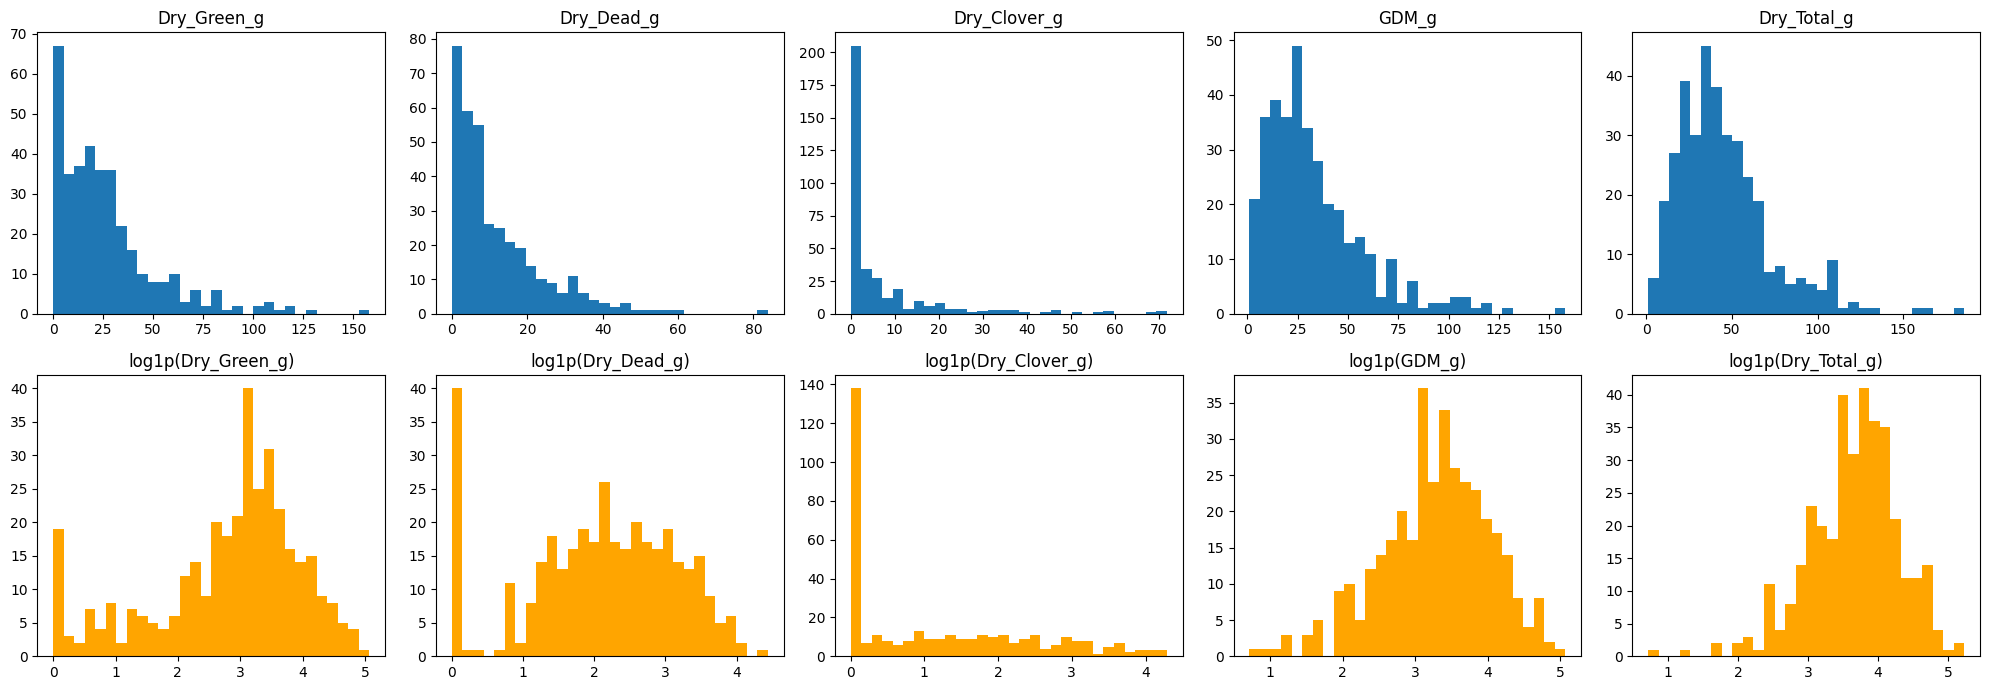

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 5, figsize=(20, 7))
for i, t in enumerate(TARGETS):
    ax[0, i].hist(df[t], bins=30)
    ax[0, i].set_title(t)
    ax[1, i].hist(np.log1p(df[t]), bins=30, color="orange")
    ax[1, i].set_title(f"log1p({t})")
plt.tight_layout()
plt.show()

**Yorum:**
- Tüm hedefler sağa çarpık: Dry_Total medyan 40.3 g, max 185.7 g
- Log1p sonrası GDM ve Dry_Total neredeyse simetrik, modelleri log ölçeğinde eğitmeliyiz.
- Dry_Green ve Dry_Dead'de 0'da ayrı bir yığılma var.
- Dry_Clover'ın %37.8'i sıfır, en zor hedef bu olacak.